# 11 — Why high charge looked hard: outliers, not architectures

**Question.** Linear, ridge, trees, MLP, CNN, RNN, GRU and LSTM were tried on three charge regimes. Most seemed to
work at low charge and to be limited at high charge. Is that the models, the data preparation, or the metric?

**Setting** (`scripts/regimes.py`, used by every notebook here): same-shot charge (virtual diagnostic), one row per
shot of the clean segments in `results/datasets/`. Per segment, test = last 10 %, validation = last 10 % of the
rest. Dropouts (< 30 % of the trailing median) are never trained on or scored.

| Regime | Segments | Level |
|---|---|---|
| low charge | 0, 2, 3, 4 | 0.1–0.25 nC |
| high, repetitive | 5 | ~5.5 nC |
| high, non-repetitive | 1, 6, 7 | 5–10 nC |

**Framing.** charge = level × exp(jitter). The level is a causal trailing mean of the past BCM; the models predict the
jitter from the *fast parts* of the instruments (reading minus its own trailing mean).

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parents[1] if Path.cwd().name == "adnan" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from regimes import load, score, REGIMES, NOISE_FLOOR_PCT
R = ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
REG_COL = {"low": "tab:blue", "high_rep": "tab:orange", "high_nonrep": "tab:green"}
SEG_ORDER = [0, 3, 4, 5, 1, 6, 7]
def segcols(df):
    return [c for c in SEG_ORDER if c in set(df.columns.get_level_values(-1))]

## 1. The fast parts have heavy tails

A handful of shots per segment have huge fast parts: camera dark frames and spikes, and BCM readings far off the
level but above the 30 % dropout cut. Below: the BCM jitter against the camera's fast part, as prepared and with the
robust preparation (`load(robust=5)`: readings beyond 5 robust sigmas become missing, those shots' camera group is
blanked; shots whose jitter is beyond 5 robust sigmas are not trained on, but are still scored).

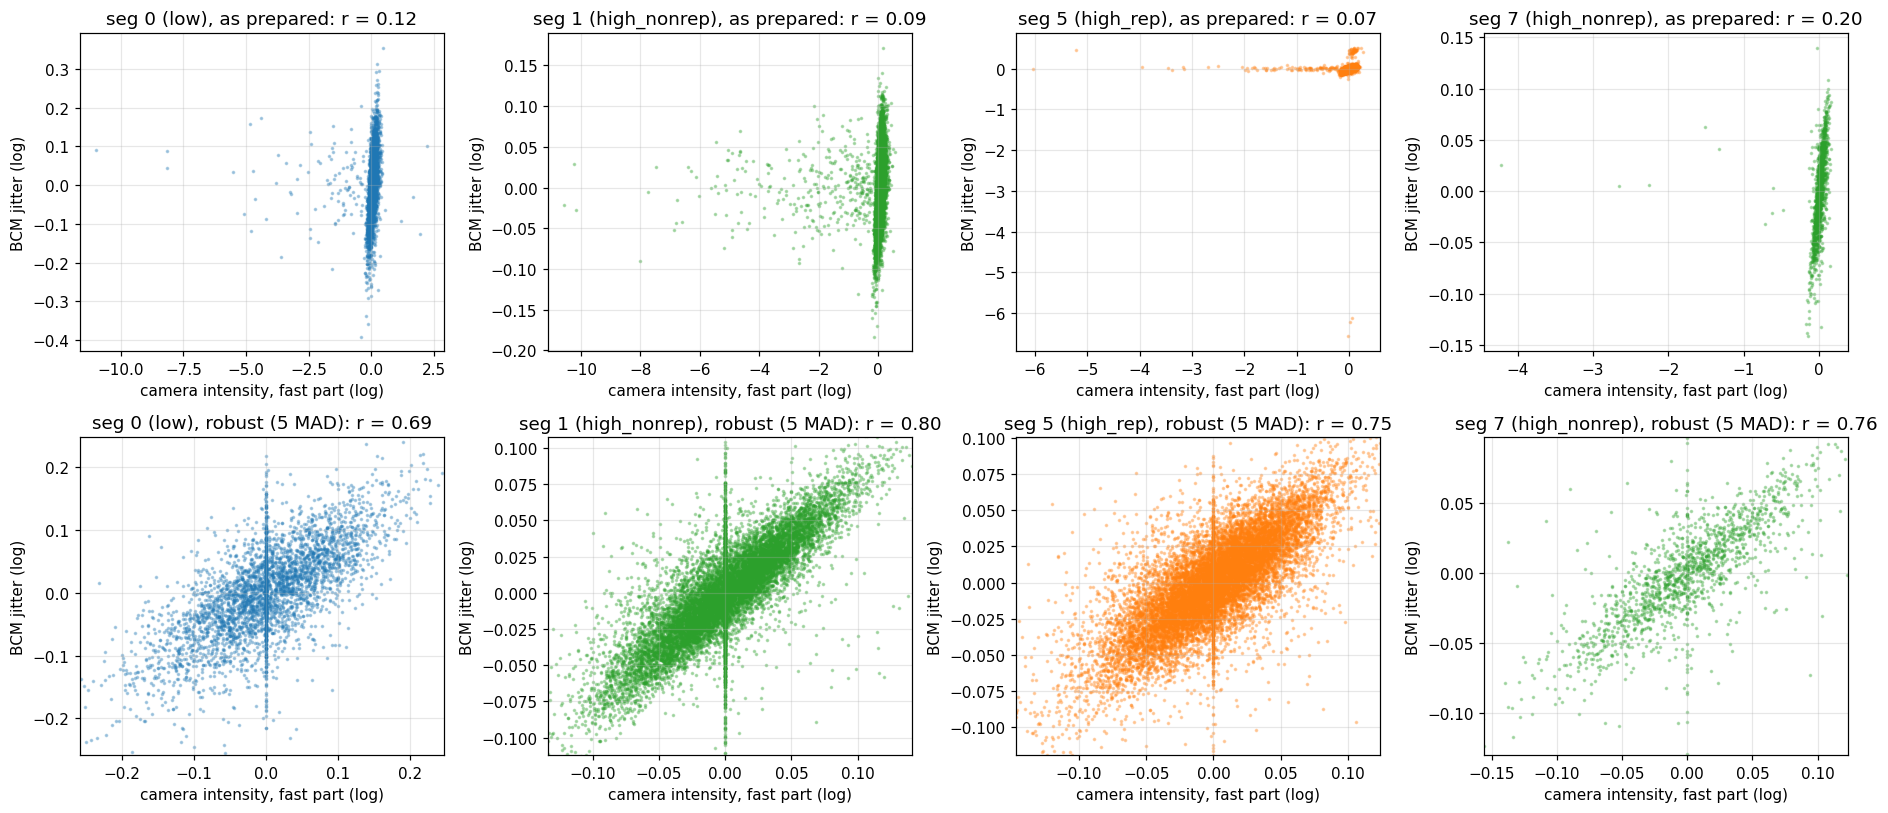

In [2]:
raw, names = load(R.parent / "results/datasets")
rob, _ = load(R.parent / "results/datasets", robust=5)
ci, li = names.index("BTV_intensity"), names.index("lab_laser_power")
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for col, s in enumerate([0, 1, 5, 7]):
    for row, (segs, tag) in enumerate([(raw, "as prepared"), (rob, "robust (5 MAD)")]):
        g = segs[s]; m = g["fit"]
        x, j = g["Xfast"][m, ci], g["jitter"][m]
        r = np.corrcoef(j, x)[0, 1]
        ax = axes[row, col]
        ax.scatter(x, j, s=2, alpha=0.3, color=REG_COL[g["regime"]])
        ax.set_title(f"seg {s} ({g['regime']}), {tag}: r = {r:.2f}")
        ax.set_xlabel("camera intensity, fast part (log)"); ax.set_ylabel("BCM jitter (log)")
        if row == 1:
            ax.set_xlim(np.percentile(x, [0.2, 99.8])); ax.set_ylim(np.percentile(j, [0.2, 99.8]))
fig.tight_layout()

In [3]:
rows = []
for s in SEG_ORDER:
    for tag, segs in (("as prepared", raw), ("robust", rob)):
        g = segs[s]; m = g["fit"]
        rows.append({"segment": s, "regime": g["regime"], "prep": tag,
                     "r camera": np.corrcoef(g["jitter"][m], g["Xfast"][m, ci])[0, 1],
                     "r lab": np.corrcoef(g["jitter"][m], g["Xfast"][m, li])[0, 1],
                     "training shots": int(m.sum())})
corr = pd.DataFrame(rows).pivot_table(index="prep", columns="segment", values=["r camera", "r lab", "training shots"])
corr.round(2)

r camera                                    r lab             ...  \
segment            0     1     3     4     5    6     7     0     1    3  ...   
prep                                                                      ...   
as prepared     0.12  0.09  0.17  0.23  0.07  0.8  0.20  0.32  0.59  0.2  ...   
robust          0.69  0.80  0.64  0.55  0.75  0.8  0.76  0.32  0.59  0.2  ...   

                              training shots                           \
segment         5     6     7              0        1       3       4   
prep                                                                    
as prepared  0.18  0.88  0.39         3731.0  13039.0  4337.0  3109.0   
robust       0.57  0.87  0.39         3729.0  13036.0  4332.0  3098.0   

                                      
segment            5       6       7  
prep                                  
as prepared  13634.0  2558.0  1438.0  
robust       13578.0  2556.0  1438.0  

[2 rows x 21 columns]

**Reading.** The camera's correlation with the charge jitter goes from 0.07–0.20 to 0.69–0.80 on segments 0, 1, 5
and 7 once the spikes are treated as missing; only 3–56 training shots per segment are dropped. Seg 6 had no such
outliers and was already at 0.80. Spearman gives the same picture on the raw data, which is the quick check for
this kind of problem.

## 2. What that does to the models

`scripts/regime_bench.py`, all nine families, same split and score. Left: as prepared; right: robust preparation
plus the level filter chosen in notebook 12. MAE in % of the level on the test shots (lower is better).

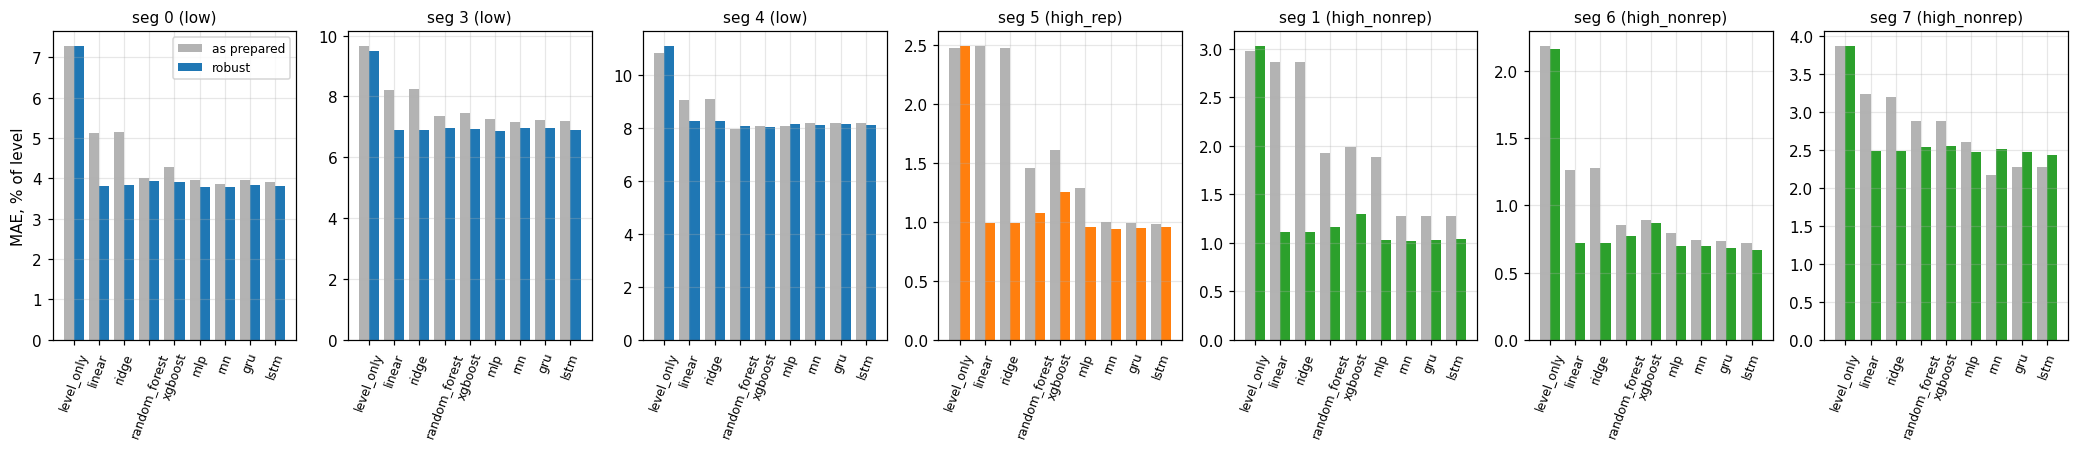

In [4]:
def bench(path):
    d = pd.read_csv(path)
    d = d[(d.framing == "jitter") & (d.pool == "regime")]
    return d.pivot_table(index="model", columns="segment", values="mae_pct")
before = bench(R / "regime_bench/scores.csv")
after = bench(R / "regime_bench_robust_filters/scores.csv")
models = ["level_only", "linear", "ridge", "random_forest", "xgboost", "mlp", "rnn", "gru", "lstm"]
fig, axes = plt.subplots(1, 7, figsize=(19, 4.2), sharey=False)
for ax, s in zip(axes, SEG_ORDER):
    x = np.arange(len(models))
    ax.bar(x - 0.2, before.loc[models, s], 0.4, label="as prepared", color="0.7")
    ax.bar(x + 0.2, after.loc[models, s], 0.4, label="robust", color=REG_COL[rob[s]["regime"]])
    ax.set_xticks(x, models, rotation=70, fontsize=8); ax.set_title(f"seg {s} ({rob[s]['regime']})", fontsize=10)
axes[0].set_ylabel("MAE, % of level"); axes[0].legend(fontsize=8)
fig.tight_layout()

In [5]:
pd.concat({"as prepared": before.loc[models, SEG_ORDER], "robust": after.loc[models, SEG_ORDER]}, axis=1).round(2)

as prepared                                      robust        \
segment                 0     3      4     5     1     6     7      0     3   
model                                                                         
level_only           7.28  9.66  10.82  2.48  2.98  2.18  3.87   7.28  9.50   
linear               5.11  8.22   9.03  2.49  2.87  1.26  3.24   3.82  6.89   
ridge                5.15  8.23   9.08  2.47  2.86  1.28  3.20   3.83  6.89   
random_forest        4.00  7.35   7.96  1.46  1.93  0.86  2.89   3.93  6.95   
xgboost              4.29  7.46   8.07  1.61  1.99  0.89  2.88   3.92  6.93   
mlp                  3.96  7.25   8.07  1.29  1.89  0.79  2.61   3.78  6.87   
rnn                  3.87  7.17   8.18  1.00  1.28  0.75  2.18   3.78  6.98   
gru                  3.95  7.24   8.18  0.99  1.28  0.74  2.27   3.82  6.98   
lstm                 3.90  7.18   8.16  0.98  1.27  0.72  2.28   3.81  6.91   

                                              
segment            4     5     1     6     7  
model                                         
level_only     11.09  2.49  3.03  2.16  3.87  
linear          8.26  0.99  1.12  0.72  2.48  
ridge           8.25  0.99  1.12  0.72  2.48  
random_forest   8.07  1.07  1.16  0.77  2.54  
xgboost         8.02  1.26  1.30  0.87  2.56  
mlp             8.14  0.96  1.03  0.69  2.47  
rnn             8.11  0.94  1.02  0.70  2.51  
gru             8.14  0.95  1.03  0.68  2.47  
lstm            8.11  0.95  1.04  0.67  2.44

**Reading.**
- As prepared, linear and ridge are no better than the level alone on seg 5 (2.48 %) and seg 1 (2.86 %), while the
  GRU / RNN / LSTM reach 0.99 % and 1.28 %. That is the "limited at high charge" impression.
- After robust preparation the ridge reaches 0.99 % and 1.12 %, within ~5–10 % of the recurrent networks. **The
  recurrent networks were not better at high charge, they were robust by accident:** L1 loss and inputs clipped at
  5 sigmas ignore the outliers that least squares chases.
- Trees (random forest, XGBoost) are the weakest family at high charge after the fix.
- Low charge barely changes: the models were already near the BCM's own noise there (notebook 13).

## 3. The metric matters too

The same models scored with R² on the raw charge (absolute framing, one model per segment, as in
`08_simple_models.ipynb`).

In [6]:
d = pd.read_csv(R / "regime_bench/scores.csv")
d = d[(d.framing == "absolute")]
pd.concat({"R2": d.pivot_table(index="model", columns="segment", values="r2").loc[models],
           "MAE %": d.pivot_table(index="model", columns="segment", values="mae_pct").loc[models]}, axis=1).round(2)

R2                                      MAE %               \
segment           0     1     3     4     5     6     7      0     1      3   
model                                                                         
level_only    -1.28 -0.00 -0.39 -0.64 -2.92 -1.47 -0.08  11.79  5.09  12.25   
linear         0.37  0.46  0.21  0.55  0.16  0.85  0.87   6.09  3.50   8.40   
ridge          0.29  0.47  0.20  0.51  0.15  0.85  0.86   6.58  3.47   8.50   
random_forest  0.46  0.76  0.33  0.57  0.79  0.75  0.23   5.53  2.25   7.41   
xgboost        0.52  0.79  0.30  0.57 -1.04  0.83  0.18   5.17  2.15   7.71   
mlp            0.60  0.81  0.32  0.57  0.85  0.87  0.88   4.71  1.97   7.18   
rnn            0.66  0.82  0.32  0.64  0.86  0.91  0.44   4.18  1.96   7.34   
gru            0.66  0.84  0.34  0.65  0.86  0.90  0.48   4.30  1.94   7.06   
lstm           0.63  0.82  0.33  0.65  0.86  0.90  0.32   4.47  2.04   7.22   

                                        
segment            4     5     6     7  
model                                   
level_only     19.76  7.87  3.53  4.37  
linear          8.91  2.90  0.87  2.58  
ridge           9.35  2.98  0.87  2.64  
random_forest   8.70  1.49  1.09  2.50  
xgboost         8.80  5.53  0.92  2.31  
mlp             8.80  1.24  0.81  1.54  
rnn             8.26  1.22  0.65  1.93  
gru             8.11  1.23  0.68  2.15  
lstm            8.21  1.20  0.67  2.22

**Reading.** XGBoost has R² = −1.0 on seg 5 with an MAE of 5.5 %, and 0.18 on seg 7 with 2.3 %. At high charge the
test region's variance is small and trees cannot extrapolate a level they never saw, so R² on the raw charge swings
wildly. **Compare models with MAE in % of the level and the fraction of jitter explained, per regime.**